In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
from tqdm import tqdm
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
   for filename in tqdm(filenames):
        os.path.join(dirname, filename)

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

0it [00:00, ?it/s]
100%|██████████| 15000/15000 [00:00<00:00, 943855.26it/s]


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df_ss=pd.read_csv('/kaggle/input/vinbigdata-chest-xray-abnormalities-detection/sample_submission.csv')
df_tr=pd.read_csv('/kaggle/input/vinbigdata-chest-xray-abnormalities-detection/train.csv')
print('Training Data sample')
print(df_tr.head())
print("\nData description")
print(df_tr.info())
print(df_tr.describe(include='all'))
print('-------------\n Submission Sample')
print(df_ss.head())
print(df_ss.info())
print(df_ss.describe(include='all'))



/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


Training Data sample
                           image_id          class_name  class_id rad_id  \
0  50a418190bc3fb1ef1633bf9678929b3          No finding        14    R11   
1  21a10246a5ec7af151081d0cd6d65dc9          No finding        14     R7   
2  9a5094b2563a1ef3ff50dc5c7ff71345        Cardiomegaly         3    R10   
3  051132a778e61a86eb147c7c6f564dfe  Aortic enlargement         0    R10   
4  063319de25ce7edb9b1c6b8881290140          No finding        14    R10   

    x_min   y_min   x_max   y_max  
0     NaN     NaN     NaN     NaN  
1     NaN     NaN     NaN     NaN  
2   691.0  1375.0  1653.0  1831.0  
3  1264.0   743.0  1611.0  1019.0  
4     NaN     NaN     NaN     NaN  

Data description
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 67914 entries, 0 to 67913
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   image_id    67914 non-null  object 
 1   class_name  67914 non-null  object 
 2   class_id   

/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


In [3]:
print(df_tr['class_name'].value_counts())

class_name
No finding            31818
Aortic enlargement     7162
Cardiomegaly           5427
Pleural thickening     4842
Pulmonary fibrosis     4655
Nodule/Mass            2580
Lung Opacity           2483
Pleural effusion       2476
Other lesion           2203
Infiltration           1247
ILD                    1000
Calcification           960
Consolidation           556
Atelectasis             279
Pneumothorax            226
Name: count, dtype: int64


 Found 18000 DICOM files.
Example file path: /kaggle/input/vinbigdata-chest-xray-abnormalities-detection/test/83caa8a85e03606cf57e49147d7ac569.dicom


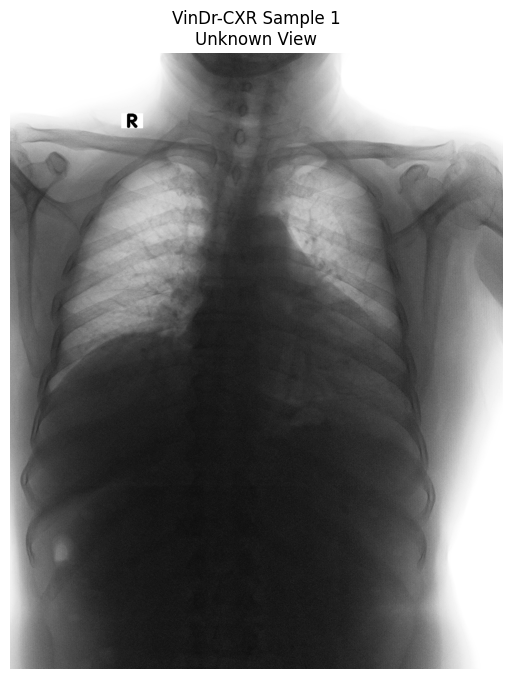

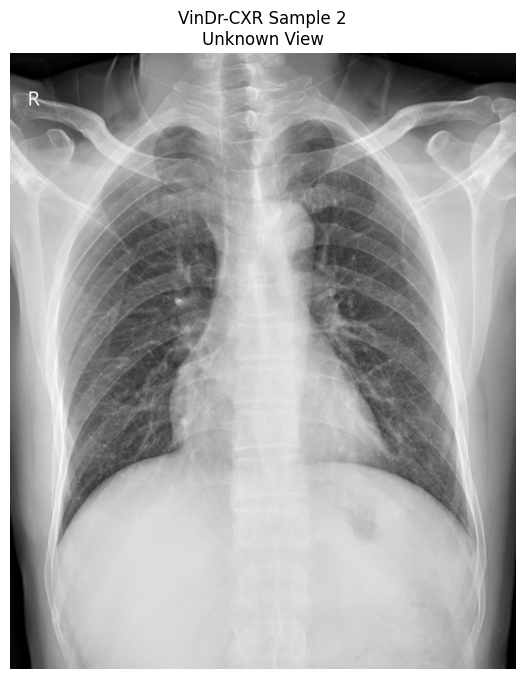

In [4]:
import pydicom
# Step 1: Automatically find the folder containing DICOMs
dicom_files = []
for root, _, files in os.walk('/kaggle/input'):
    for f in files:
        if f.lower().endswith(('.dcm', '.dicom')):
            dicom_files.append(os.path.join(root, f))

# Step 2: Check if any files found
if len(dicom_files) == 0:
    print("No DICOM files found in /kaggle/input. Check your dataset structure.")
else:
    print(f" Found {len(dicom_files)} DICOM files.")
    print("Example file path:", dicom_files[0])

    # Step 3: Visualize first two DICOMs with metadata
    for i in range(min(2, len(dicom_files))):
        dicom_path = dicom_files[i]
        dicom_data = pydicom.dcmread(dicom_path)
        image = dicom_data.pixel_array

        # Normalize for better visualization
        image = (image - image.min()) / (image.max() - image.min())
        # Display image
        plt.figure(figsize=(8,8))
        plt.imshow(image, cmap='gray')
        plt.title(f"VinDr-CXR Sample {i+1}\n{dicom_data.get('ViewPosition', 'Unknown View')}")
        plt.axis('off')
        plt.show()


In [5]:
img_id = "9a5094b2563a1ef3ff50dc5c7ff71345"  
df_tr[df_tr["image_id"] == img_id]


,image_id,class_name,class_id,rad_id,x_min,y_min,x_max,y_max
2,9a5094b2563a1ef3ff50dc5c7ff71345,Cardiomegaly,3,R10,691.0,1375.0,1653.0,1831.0
5517,9a5094b2563a1ef3ff50dc5c7ff71345,Pleural effusion,10,R9,1789.0,1729.0,1875.0,1992.0
25023,9a5094b2563a1ef3ff50dc5c7ff71345,Pleural thickening,11,R9,1789.0,1729.0,1875.0,1992.0
26165,9a5094b2563a1ef3ff50dc5c7ff71345,Cardiomegaly,3,R9,692.0,1375.0,1657.0,1799.0
42709,9a5094b2563a1ef3ff50dc5c7ff71345,Cardiomegaly,3,R8,689.0,1313.0,1666.0,1763.0
53473,9a5094b2563a1ef3ff50dc5c7ff71345,Aortic enlargement,0,R9,1052.0,715.0,1299.0,966.0


In [ ]:

import pydicom
import numpy as np
import cv2
import os
from tqdm import tqdm

def preprocess_image(dcm_path, png_path=None):
    """
    Loads a DICOM image, preprocesses it, and optionally saves it as PNG.
    """

    # Load DICOM
    dcm = pydicom.dcmread(dcm_path)
    img = dcm.pixel_array.astype(np.float32)

    #Convertig to Grayscale 
    if len(img.shape) == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Resize → 512x512
    img = cv2.resize(img, (512, 512))

    # Min–max normalization
    img = (img - img.min()) / (img.max() - img.min() + 1e-6)

    # CLAHE enhancement
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    img = clahe.apply((img * 255).astype(np.uint8))

    # Denoising
    img = cv2.GaussianBlur(img, (3, 3), 0)

    #  Median Filter 
    img = cv2.medianBlur(img, 3)

    # Crop borders
    img = img[5:-5, 5:-5]

    # Pad back to 512x512
    img = cv2.copyMakeBorder(img, 5, 5, 5, 5, cv2.BORDER_REPLICATE)

    #  If PNG path is provided, save the image
    if png_path is not None:
        os.makedirs(os.path.dirname(png_path), exist_ok=True)
        cv2.imwrite(png_path, img)

    return img

def safe_augment(img):
    
    # horizontal flip
    if np.random.rand() < 0.4:
        img = cv2.flip(img, 1)

    # rotation
    if np.random.rand() < 0.3:
        angle = np.random.uniform(-5, 5)
        h, w = img.shape
        M = cv2.getRotationMatrix2D((w//2, h//2), angle, 1)
        img = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)

    # contrast variation
    if np.random.rand() < 0.3:
        img = cv2.convertScaleAbs(img, alpha=1.05, beta=2)

    return img

def convert_bbox_to_yolo(row, orig_w, orig_h, img_w, img_h):
    if pd.isna(row["x_min"]):
        return None

    x_min = row["x_min"]
    y_min = row["y_min"]
    x_max = row["x_max"]
    y_max = row["y_max"]

    # scale bbox to resized image dimensions
    x_min = x_min * img_w / orig_w
    x_max = x_max * img_w / orig_w
    y_min = y_min * img_h / orig_h
    y_max = y_max * img_h / orig_h

    # convert to YOLO format
    xc = (x_min + x_max) / 2 / img_w
    yc = (y_min + y_max) / 2 / img_h
    w = (x_max - x_min) / img_w
    h = (y_max - y_min) / img_h

    return row["class_id"], xc, yc, w, h




In [7]:
INPUT_DIR = "/kaggle/input/vinbigdata-chest-xray-abnormalities-detection/train/"
OUTPUT_DIR = "/kaggle/working/pre_processed_3000/"
LABEL_DIR = os.path.join(OUTPUT_DIR, "labels")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(LABEL_DIR, exist_ok=True)

all_files = [f for f in os.listdir(INPUT_DIR) if f.endswith(".dicom")]
selected_files = all_files[:3000]  

print(f"Preprocessing {len(selected_files)} images...\n")

for file in tqdm(selected_files):
    dcm_path = os.path.join(INPUT_DIR, file)
    image_id = file.replace(".dicom", "")

    dcm = pydicom.dcmread(dcm_path)
    orig_h, orig_w = dcm.pixel_array.shape

    # Preprocess original image
    img = preprocess_image(dcm_path)
    img_h, img_w = img.shape[:2]

    save_path = os.path.join(OUTPUT_DIR, file.replace(".dicom", ".png"))
    cv2.imwrite(save_path, img)

    # Save augmented version
    aug_img = safe_augment(img)
    aug_path = os.path.join(OUTPUT_DIR, file.replace(".dicom", "_aug.png"))
    cv2.imwrite(aug_path, aug_img)

    rows = df_tr[df_tr["image_id"] == image_id]  # annotations for this image
    lbl_path = os.path.join(LABEL_DIR, f"{image_id}.txt")

    with open(lbl_path, "w") as f:
        for _, r in rows.iterrows():
            box = convert_bbox_to_yolo(r, orig_w, orig_h, img_w, img_h)
            if box:
                cls, xc, yc, w, h = box
                f.write(f"{cls} {xc} {yc} {w} {h}\n")


    lbl_aug_path = os.path.join(LABEL_DIR, f"{image_id}_aug.txt")
    with open(lbl_aug_path, "w") as f:
        for _, r in rows.iterrows():
            box = convert_bbox_to_yolo(r, orig_w, orig_h, img_w, img_h)

            if box:
                cls, xc, yc, w, h = box
                f.write(f"{cls} {xc} {yc} {w} {h}\n")



Preprocessing 3000 images...



100%|██████████| 3000/3000 [1:18:26<00:00,  1.57s/it]


In [8]:
import pandas as pd
import os

DATA_DIR = "/kaggle/working/pre_processed_3000/"
IMG_DIR = DATA_DIR
CSV_ORIGINAL = "/kaggle/input/vinbigdata-chest-xray-abnormalities-detection/train.csv"
CSV_PATH = os.path.join(DATA_DIR, "labels.csv")

# Read original CSV
df = pd.read_csv(CSV_ORIGINAL)

# Keep only images preprocessed
png_files = set([f for f in os.listdir(IMG_DIR) if f.endswith(".png")])
df['png_file'] = df['image_id'].apply(lambda x: x+".png")
df_filtered = df[df['png_file'].isin(png_files)].copy()

# Create multi-label CSV
class_names = [
    "Aortic enlargement", "Atelectasis", "Calcification", "Cardiomegaly",
    "Consolidation", "ILD", "Infiltration", "Lung Opacity", "Nodule/Mass",
    "Other lesion", "Pleural effusion", "Pleural thickening", "Pneumothorax",
    "Pulmonary fibrosis"
]
num_classes = len(class_names)

labels_dict = {f: [0]*num_classes for f in df_filtered['png_file'].unique()}
for _, row in df_filtered.iterrows():
    class_id = int(row['class_id'])
    img_file = row['png_file']
    if 0 <= class_id < num_classes:
        labels_dict[img_file][class_id] = 1

# Build labels DataFrame
labels_list = [[k] + v for k,v in labels_dict.items()]
labels_df = pd.DataFrame(labels_list, columns=['image_id'] + class_names)
labels_df.to_csv(CSV_PATH, index=False)
print(" labels.csv filtered and saved!")


 labels.csv filtered and saved!


In [21]:

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from torchvision.models import efficientnet_b0, resnet50
from sklearn.metrics import roc_auc_score, f1_score
from PIL import Image

# ------------------------------
# Step 0 — CONFIG
# ------------------------------
DATA_DIR = "/kaggle/working/pre_processed_3000/"
IMG_DIR = DATA_DIR
CSV_PATH = os.path.join(DATA_DIR, "labels.csv")

BATCH_SIZE = 32
LR = 1e-3
EPOCHS = 20
IMG_SIZE = 512
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


# ------------------------------
# Step 1 — Dataset + DataLoader
# ------------------------------
class ChestXrayDataset(Dataset):
    def __init__(self, df, img_dir, transform=None):
        self.df = df
        self.img_dir = img_dir
        self.transform = transform
        self.labels = self.df.iloc[:, 1:].values.astype("float32")
        self.image_ids = self.df["image_id"].values

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.image_ids[idx])
        img = Image.open(img_path).convert("RGB")

        if self.transform:
            img = self.transform(img)

        label = torch.tensor(self.labels[idx])

        return img, label

# transforms
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])


df = pd.read_csv(CSV_PATH)
# split
train_df = df.sample(frac=0.8, random_state=42)
val_df = df.drop(train_df.index)

train_dataset = ChestXrayDataset(train_df, IMG_DIR, train_transform)
val_dataset = ChestXrayDataset(val_df, IMG_DIR, val_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE)

print(" Data loaded successfully")

# ------------------------------
# Step 2 — Select ML Model
# ------------------------------

USE_MODEL = "efficientnet"   # options: efficientnet, resnet

if USE_MODEL == "efficientnet":
    model = efficientnet_b0(weights="DEFAULT")
    num_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(num_features, df.shape[1] - 1)

elif USE_MODEL == "resnet":
    model = resnet50(weights="DEFAULT")
    num_features = model.fc.in_features
    model.fc = nn.Linear(num_features, df.shape[1] - 1)

model = model.to(DEVICE)

# ------------------------------
# Step 3 — Modify final layer + Loss
# ------------------------------

criterion = nn.BCEWithLogitsLoss()  # multi-label loss
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

scaler = torch.cuda.amp.GradScaler()   # for mixed precision

# ------------------------------
# Step 4 — Training + Validation
# ------------------------------
train_losses = []
val_losses = []
val_f1_scores = []

best_f1 = 0

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0

    for imgs, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"):
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()

        with torch.cuda.amp.autocast():
            outputs = model(imgs)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)
    train_losses.append(train_loss)

    # -------- VALIDATION --------
    model.eval()
    val_running_loss = 0
    all_labels = []
    all_preds = []

    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            outputs = model(imgs)

            loss = criterion(outputs, labels)
            val_running_loss += loss.item()

            preds = torch.sigmoid(outputs).detach().cpu().numpy()
            all_preds.append(preds)
            all_labels.append(labels.cpu().numpy())

    val_loss = val_running_loss / len(val_loader)
    val_losses.append(val_loss)

    all_preds = np.vstack(all_preds)
    all_labels = np.vstack(all_labels)

    f1 = f1_score(all_labels, all_preds > 0.5, average="macro")
    val_f1_scores.append(f1)

    try:
        auc = roc_auc_score(all_labels, all_preds, average="macro")
    except:
        auc = 0.0

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")
    print(f"F1 Score: {f1:.4f} | AUC-ROC: {auc:.4f}")

    # Save best model
    if f1 > best_f1:
        best_f1 = f1
        torch.save(model.state_dict(), "/kaggle/working/best_model.hcl")
        print("✔ Best model saved!")


print("\nTraining Completed Successfully.")




 Data loaded successfully


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100%|██████████| 20.5M/20.5M [00:00<00:00, 139MB/s] 
/tmp/ipykernel_47/970346686.py:100: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()   # for mixed precision
Epoch 1/20:   0%|          | 0/75 [00:00<?, ?it/s]/tmp/ipykernel_47/970346686.py:120: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 1/20: 100%|██████████| 75/75 [00:50<00:00,  1.48it/s]



Epoch 1/20
Train Loss: 0.2191 | Val Loss: 0.1666
F1 Score: 0.1011 | AUC-ROC: 0.8963
✔ Best model saved!


Epoch 2/20:   0%|          | 0/75 [00:00<?, ?it/s]/tmp/ipykernel_47/970346686.py:120: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 2/20: 100%|██████████| 75/75 [00:46<00:00,  1.63it/s]



Epoch 2/20
Train Loss: 0.1606 | Val Loss: 0.1814
F1 Score: 0.1463 | AUC-ROC: 0.8862
✔ Best model saved!


...


Epoch 18/20
Train Loss: 0.0629 | Val Loss: 0.1571
F1 Score: 0.4437 | AUC-ROC: 0.9269
✔ Best model saved!


Epoch 19/20:   0%|          | 0/75 [00:00<?, ?it/s]/tmp/ipykernel_47/970346686.py:120: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 19/20: 100%|██████████| 75/75 [00:48<00:00,  1.56it/s]



Epoch 19/20
Train Loss: 0.0581 | Val Loss: 0.1662
F1 Score: 0.3573 | AUC-ROC: 0.9060


Epoch 20/20:   0%|          | 0/75 [00:00<?, ?it/s]/tmp/ipykernel_47/970346686.py:120: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 20/20: 100%|██████████| 75/75 [00:48<00:00,  1.56it/s]



Epoch 20/20
Train Loss: 0.0617 | Val Loss: 0.1632
F1 Score: 0.4339 | AUC-ROC: 0.9134

Training Completed Successfully.


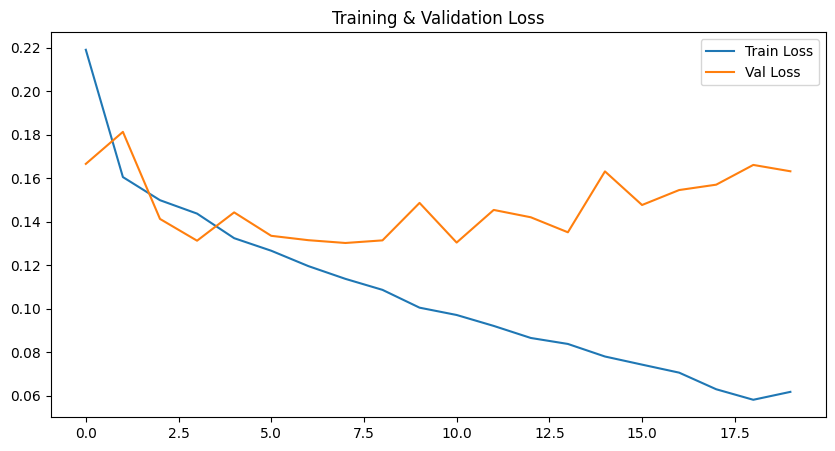

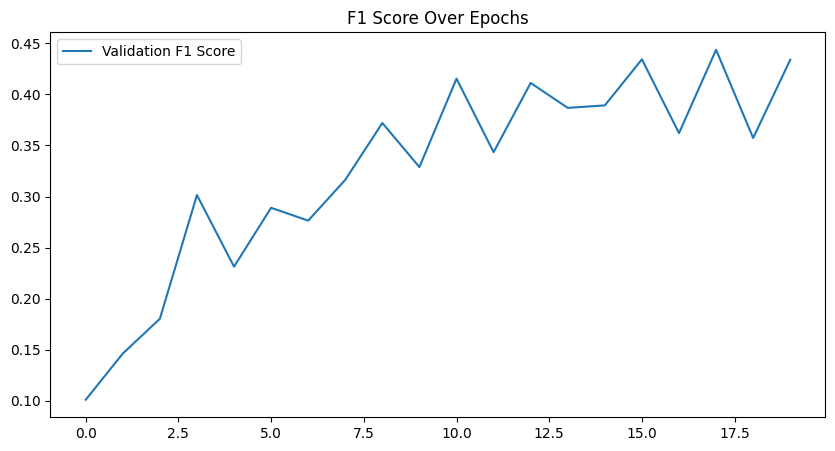

In [22]:
# ------------------------------
# Step 5 — Plot curves
# ------------------------------
plt.figure(figsize=(10,5))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.legend()
plt.title("Training & Validation Loss")
plt.show()

plt.figure(figsize=(10,5))
plt.plot(val_f1_scores, label="Validation F1 Score")
plt.legend()
plt.title("F1 Score Over Epochs")
plt.show()


In [9]:
import os
import shutil
import random

BASE = "/kaggle/working/pre_processed_3000/"
IMG_DIR = BASE
LBL_DIR = os.path.join(BASE, "labels")

OUT = "/kaggle/working/yolo_dataset/"
os.makedirs(OUT, exist_ok=True)

os.makedirs(os.path.join(OUT, "images/train"), exist_ok=True)
os.makedirs(os.path.join(OUT, "images/val"), exist_ok=True)
os.makedirs(os.path.join(OUT, "labels/train"), exist_ok=True)
os.makedirs(os.path.join(OUT, "labels/val"), exist_ok=True)

# list all PNG files (including _aug.png)
all_imgs = [f for f in os.listdir(IMG_DIR) if f.endswith(".png")]
print("Total images found:", len(all_imgs))

# train/val split
random.seed(42)
random.shuffle(all_imgs)
train_split = int(0.8 * len(all_imgs))

train_imgs = all_imgs[:train_split]
val_imgs = all_imgs[train_split:]

def move_files(split_imgs, split):
    for img_file in split_imgs:
        img_src = os.path.join(IMG_DIR, img_file)

        # label file name
        lbl_file = img_file.replace(".png", ".txt")
        lbl_src = os.path.join(LBL_DIR, lbl_file)

        # destination
        img_dst = os.path.join(OUT, f"images/{split}", img_file)
        lbl_dst = os.path.join(OUT, f"labels/{split}", lbl_file)

        shutil.copy(img_src, img_dst)

        if os.path.exists(lbl_src):
            shutil.copy(lbl_src, lbl_dst)
        else:
            # YOLO requires empty txt file if no boxes
            open(lbl_dst, "w").close()

move_files(train_imgs, "train")
move_files(val_imgs, "val")

print("YOLO dataset folder created successfully!")


Total images found: 6000
YOLO dataset folder created successfully!


In [ ]:

import yaml

yaml_path = "/kaggle/working/yolo_dataset/dataset.yaml"

data_config = {
    "train": "/kaggle/working/yolo_dataset/images/train",
    "val": "/kaggle/working/yolo_dataset/images/val",
    "names": {
        0: "Aortic enlargement",
        1: "Atelectasis",
        2: "Calcification",
        3: "Cardiomegaly",
        4: "Consolidation",
        5: "ILD",
        6: "Infiltration",
        7: "Lung Opacity",
        8: "Nodule/Mass",
        9: "Other lesion",
        10: "Pleural effusion",
        11: "Pleural thickening",
        12: "Pneumothorax",
        13: "Pulmonary fibrosis",
        14: "No finding"
    },
    "nc": 15
}

# write file
with open(yaml_path, "w") as f:
    yaml.dump(data_config, f)

print("Dataset YAML saved at:", yaml_path)


Dataset YAML saved at: /kaggle/working/yolo_dataset/dataset.yaml


In [12]:
!pip install ultralytics


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 3.6 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of mkl-fft to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of mkl-random to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of mkl-umath to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 22.1 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.8/16.8 MB 102.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 8.4 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 92.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [17]:
from ultralytics import YOLO
import torch

print("GPU:", torch.cuda.is_available())

model = YOLO("yolov8n.pt")   # n = nano model (fastest)

model.train(
    data=yaml_path,
    epochs=30,
    imgsz=512,
    batch=8,
    device=0 if torch.cuda.is_available() else "cpu",
    name="vindr_yolo",
    project="/kaggle/working"
)


GPU: True
Ultralytics 8.3.235 🚀 Python-3.11.13 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo_dataset/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=vindr_yolo, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective

/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


                   all       1200       2886      0.386      0.171      0.152     0.0774
    Aortic enlargement        241        551      0.528       0.52      0.505      0.291
           Atelectasis         20         29          1          0    0.00708    0.00337
         Calcification         34         64      0.122     0.0312     0.0153    0.00617
          Cardiomegaly        184        432       0.49      0.522      0.527      0.321
         Consolidation         29         48      0.368      0.125      0.145     0.0681
                   ILD         31         79      0.163      0.264      0.131     0.0716
          Infiltration         42         88      0.304      0.243      0.186     0.0911
          Lung Opacity        106        218       0.28     0.0734     0.0955     0.0377
           Nodule/Mass         76        230      0.256     0.0739     0.0569      0.025
          Other lesion         84        183      0.196     0.0383     0.0469     0.0161
      Pleural effusio

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ff37d143a90>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.0


image 1/1 /kaggle/working/yolo_dataset/images/val/eddb92f17c33dccfc0570afd514bad73_aug.png: 512x512 (no detections), 7.0ms
Speed: 1.0ms preprocess, 7.0ms inference, 1.0ms postprocess per image at shape (1, 3, 512, 512)


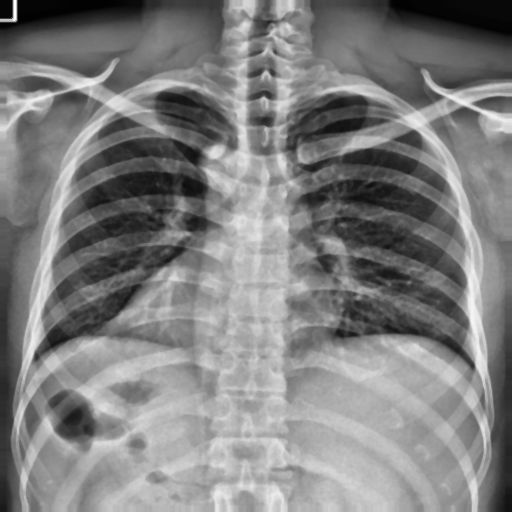

array([[[ 5,  5,  5],
        [ 5,  5,  5],
        [ 5,  5,  5],
        ...,
        [ 8,  8,  8],
        [ 8,  8,  8],
        [ 8,  8,  8]],

       [[ 5,  5,  5],
        [ 5,  5,  5],
        [ 5,  5,  5],
        ...,
        [ 8,  8,  8],
        [ 8,  8,  8],
        [ 8,  8,  8]],

       [[ 5,  5,  5],
        [ 5,  5,  5],
        [ 5,  5,  5],
        ...,
        [ 8,  8,  8],
        [ 8,  8,  8],
        [ 8,  8,  8]],

       ...,

       [[26, 26, 26],
        [26, 26, 26],
        [26, 26, 26],
        ...,
        [18, 18, 18],
        [18, 18, 18],
        [18, 18, 18]],

       [[26, 26, 26],
        [26, 26, 26],
        [26, 26, 26],
        ...,
        [18, 18, 18],
        [18, 18, 18],
        [18, 18, 18]],

       [[26, 26, 26],
        [26, 26, 26],
        [26, 26, 26],
        ...,
        [18, 18, 18],
        [18, 18, 18],
        [18, 18, 18]]], dtype=uint8)

In [41]:
best = "/kaggle/working/vindr_yolo/weights/best.pt"
m = YOLO(best)

sample = os.listdir(os.path.join(OUT, "images/val"))[0]
sample_path = os.path.join(OUT, "images/val", sample)

res = m.predict(source=sample_path, imgsz=512, conf=0.25)

res[0].plot(show=True)


In [30]:
image_id = "eddb92f17c33dccfc0570afd514bad73"
df_tr[df_tr["image_id"] == image_id]


/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


,image_id,class_name,class_id,rad_id,x_min,y_min,x_max,y_max
21170,eddb92f17c33dccfc0570afd514bad73,No finding,14,R13,NaN,NaN,NaN,NaN
21774,eddb92f17c33dccfc0570afd514bad73,No finding,14,R3,NaN,NaN,NaN,NaN
64180,eddb92f17c33dccfc0570afd514bad73,No finding,14,R16,NaN,NaN,NaN,NaN



image 1/1 /kaggle/working/yolo_dataset/images/val/23ca1279bcbf10d8dc39e769e145a516_aug.png: 512x512 1 Aortic enlargement, 1 Cardiomegaly, 1 Pleural thickening, 7.3ms
Speed: 1.1ms preprocess, 7.3ms inference, 1.2ms postprocess per image at shape (1, 3, 512, 512)


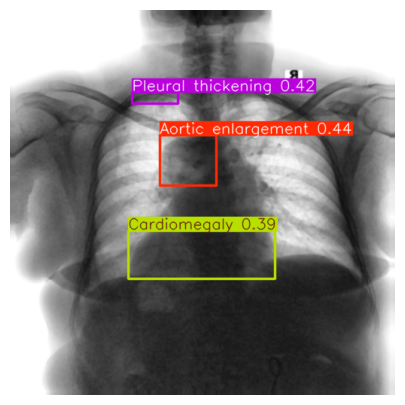


image 1/1 /kaggle/working/yolo_dataset/images/val/5ef144ed919e9b7ec53ec6e69db43849.png: 512x512 (no detections), 6.2ms
Speed: 0.9ms preprocess, 6.2ms inference, 0.6ms postprocess per image at shape (1, 3, 512, 512)


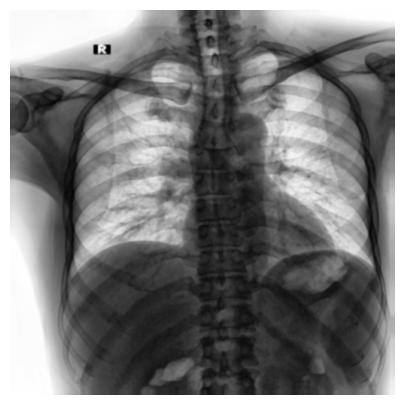


image 1/1 /kaggle/working/yolo_dataset/images/val/d56adcf249d431a30bb2bba9775e0796_aug.png: 512x512 (no detections), 6.5ms
Speed: 0.9ms preprocess, 6.5ms inference, 0.6ms postprocess per image at shape (1, 3, 512, 512)


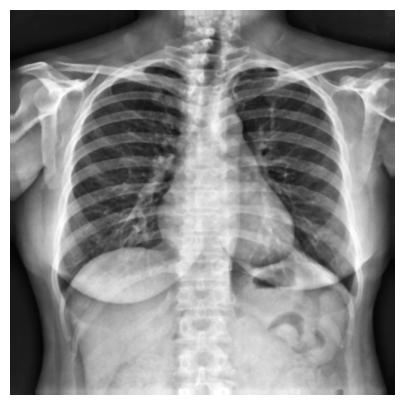


image 1/1 /kaggle/working/yolo_dataset/images/val/0ee815af6f6dc10b6e9cf697791ca809.png: 512x512 (no detections), 6.6ms
Speed: 1.0ms preprocess, 6.6ms inference, 0.5ms postprocess per image at shape (1, 3, 512, 512)


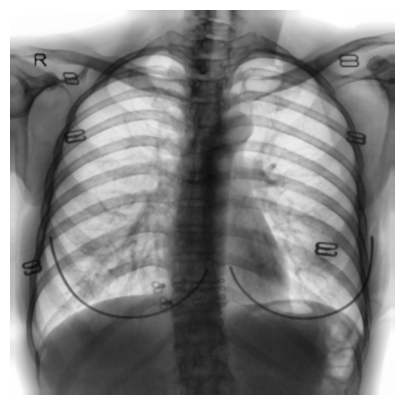


image 1/1 /kaggle/working/yolo_dataset/images/val/ddff143851d1399b550480a41b4c6fe2_aug.png: 512x512 1 Aortic enlargement, 1 Lung Opacity, 6.2ms
Speed: 0.9ms preprocess, 6.2ms inference, 1.2ms postprocess per image at shape (1, 3, 512, 512)


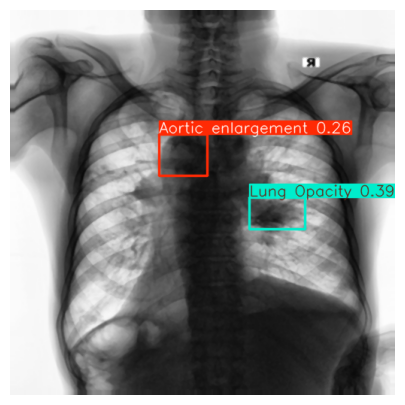

In [64]:
from ultralytics import YOLO
import os

# Load your trained model
best = "/kaggle/working/vindr_yolo/weights/best.pt"
m = YOLO(best)

# Validation folder
val_dir = os.path.join(OUT, "images/val")
val_images = os.listdir(val_dir)

# Visualize images
for img_name in val_images[10:15]:
    img_path = os.path.join(val_dir, img_name)
    
    # Run prediction with lower confidence
    res = m.predict(source=img_path, imgsz=512, conf=0.25)
    
    # Plot the results
    plt.figure(figsize=(6, 5))
    plt.imshow(res[0].plot())
    plt.axis('off')
    plt.show()
#res[0].plot(show=True)



image 1/1 /kaggle/working/yolo_dataset/images/val/7043451da60cb89537435829965759c3.png: 512x512 1 Cardiomegaly, 8.6ms
Speed: 1.1ms preprocess, 8.6ms inference, 1.1ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/working/yolo_dataset/images/val/93412e625969f373cc62e6fd703d49db.png: 512x512 (no detections), 6.1ms
Speed: 0.9ms preprocess, 6.1ms inference, 0.5ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/working/yolo_dataset/images/val/7bfa5ec72b112db0a62976f026b11e9a.png: 512x512 (no detections), 6.2ms
Speed: 1.1ms preprocess, 6.2ms inference, 0.5ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/working/yolo_dataset/images/val/30174f91133f986dd4f8f95d2b2d92b2_aug.png: 512x512 1 Aortic enlargement, 1 Cardiomegaly, 6.5ms
Speed: 1.0ms preprocess, 6.5ms inference, 1.1ms postprocess per image at shape (1, 3, 512, 512)

image 1/1 /kaggle/working/yolo_dataset/images/val/2dc8b9446edc32cb1b7ce82f5e4ae3b4.png: 512x512 (no detections)

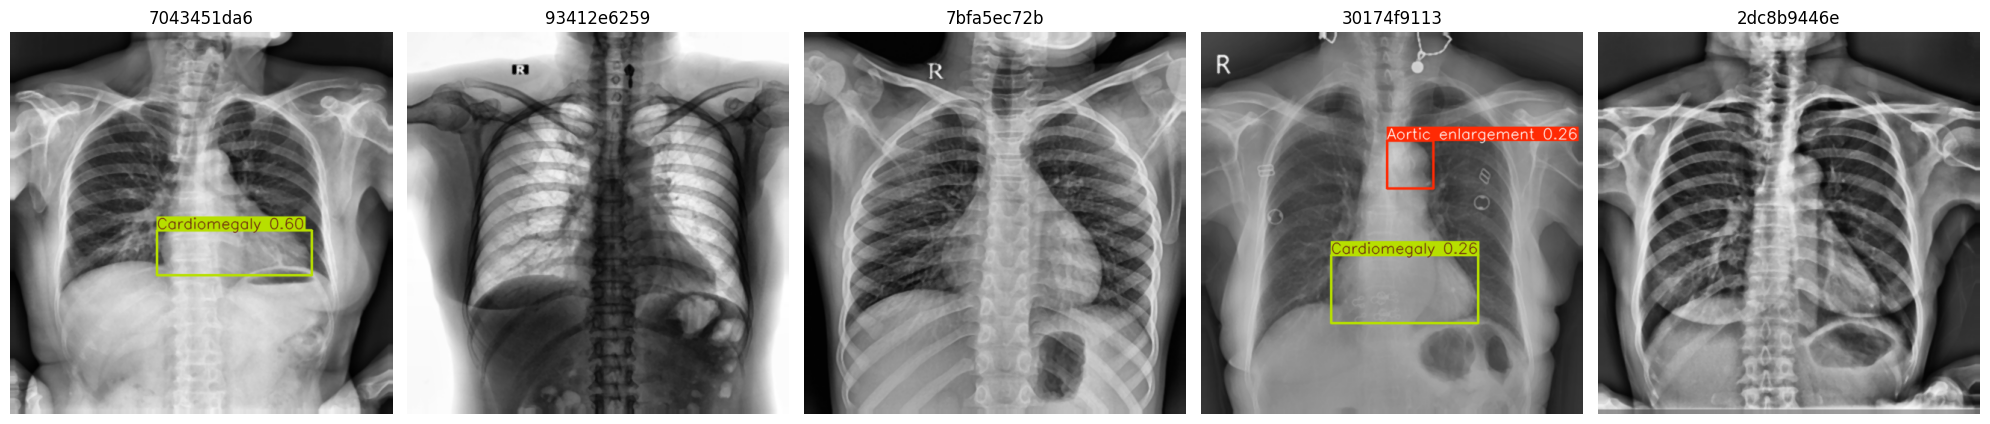

In [62]:
from ultralytics import YOLO
import os
import matplotlib.pyplot as plt

best = "/kaggle/working/vindr_yolo/weights/best.pt"
m = YOLO(best)

val_dir = os.path.join(OUT, "images/val")
val_images = os.listdir(val_dir)[15:20]  # pick first 5 images

# create a figure with 1 row, 5 columns
fig, axes = plt.subplots(1, 5, figsize=(20, 5))  # width=20, height=5 inches

for ax, img_name in zip(axes, val_images):
    img_path = os.path.join(val_dir, img_name)
    res = m.predict(source=img_path, imgsz=512, conf=0.25)
    
    ax.imshow(res[0].plot())  # plot YOLO prediction
    ax.axis('off')
    ax.set_title(img_name[:10])  # optional: show part of filename

plt.tight_layout()
plt.show()
